In [26]:
# ==================== IMPORTATION DES LIBRAIRIES ET CONFIGURATION DES CHEMINS ====================
# Ce bloc initialise l'environnement pour le prétraitement et l'entraînement des modèles.
# Il importe les librairies essentielles pour le deep learning et configure l'architecture
# des dossiers du projet AgriPredict pour un workflow organisé.

# Cellule 1 - Imports et chemins
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow import keras

# Définir les chemins
BASE_DIR = Path("..").resolve()
DATA_DIR = BASE_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
MODELS_DIR = Path("backend/models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f"✅ Chemins définis: {PROCESSED_DIR}")

✅ Chemins définis: C:\Users\Ridha\Downloads\agripredict\agripredict\data\processed


In [27]:
# ==================== CHARGEMENT ET PRÉPARATION DES DONNÉES ====================
# Ce bloc charge les données prétraitées du Sprint 2 et les prépare pour l'entraînement
# des modèles. Il gère les trois splits (train/val/test) et convertit les labels
# au format one-hot encoding requis par les modèles de classification multiclasse.

# Cellule 2 - Chargement des données
def load_processed_data(split='train'):
    split_dir = PROCESSED_DIR / split / 'numpy'
    X = np.load(split_dir / 'X.npy')
    y = np.load(split_dir / 'y.npy')

    with open(split_dir / 'metadata.json', 'r') as f:
        metadata = json.load(f)

    return X, y, metadata.get('class_names', [])

# Charger tous les splits
X_train, y_train, class_names = load_processed_data('train')
X_val, y_val, _ = load_processed_data('val')
X_test, y_test, _ = load_processed_data('test')

# One-hot encoding
num_classes = len(class_names)
y_train_onehot = keras.utils.to_categorical(y_train, num_classes=num_classes)
y_val_onehot = keras.utils.to_categorical(y_val, num_classes=num_classes)
y_test_onehot = keras.utils.to_categorical(y_test, num_classes=num_classes)

print(f"✅ Données chargées: {X_train.shape[0]} train, {X_val.shape[0]} val, {X_test.shape[0]} test")
print(f"✅ Classes: {class_names}")

✅ Données chargées: 1050 train, 224 val, 226 test
✅ Classes: ['carence_azote', 'mildiou', 'oïdium', 'sain']


In [28]:
# ==================== CRÉATION DU MODÈLE CNN BASELINE ====================
# Ce bloc construit l'architecture du modèle CNN baseline avec 3 blocs convolutionnels.
# Il sert de point de référence pour comparer les performances avec le transfer learning.
# L'architecture inclut des techniques de régularisation (BatchNorm, Dropout) pour
# améliorer la généralisation et éviter le surapprentissage.

# Cellule 3 - Création du modèle baseline
def create_baseline_cnn(input_shape=(224, 224, 3), num_classes=4):
    model = keras.Sequential([
        # Bloc 1
        keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
        keras.layers.BatchNormalization(),
        keras.layers.MaxPooling2D((2, 2)),
        keras.layers.Dropout(0.2),

        # Bloc 2
        keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        keras.layers.BatchNormalization(),
        keras.layers.MaxPooling2D((2, 2)),
        keras.layers.Dropout(0.3),

        # Bloc 3
        keras.layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        keras.layers.BatchNormalization(),
        keras.layers.MaxPooling2D((2, 2)),
        keras.layers.Dropout(0.4),

        # Couches denses
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.BatchNormalization(),
        keras.layers.Dropout(0.5),

        # Sortie
        keras.layers.Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy',
                keras.metrics.Precision(name='precision'),
                keras.metrics.Recall(name='recall'),
                keras.metrics.AUC(name='auc')]
    )

    return model

# Créer le modèle
input_shape = X_train.shape[1:]
num_classes = len(class_names)
baseline_model = create_baseline_cnn(input_shape, num_classes)

# Afficher le résumé
baseline_model.summary()

C:\Users\Ridha\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,940,356 (49.36 MB)

 Trainable params: 12,939,652 (49.36 MB)

 Non-trainable params: 704 (2.75 KB)

In [29]:
# ==================== CONFIGURATION DES CALLBACKS D'ENTRAÎNEMENT ====================
# Ce bloc configure des callbacks intelligents pour optimiser l'entraînement du modèle.
# Les callbacks automatisent des tâches cruciales comme l'arrêt précoce pour éviter
# le surapprentissage, la sauvegarde des meilleurs modèles, et l'ajustement dynamique
# du learning rate pour une convergence plus stable.

# Cellule 4 - Callbacks
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint(filepath=str(MODELS_DIR / 'best_baseline_model.h5'),
                   monitor='val_accuracy', save_best_only=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3)
]

print(f"✅ {len(callbacks)} callbacks configurés")

✅ 3 callbacks configurés


In [30]:
# ==================== ENTRAÎNEMENT DU MODÈLE BASELINE ====================
# Ce bloc exécute l'entraînement du modèle CNN baseline en utilisant les données
# préparées et les callbacks configurés. Il inclut une gestion intelligente des
# déséquilibres de classes via les poids de classe, et mesure le temps d'entraînement
# pour évaluer l'efficacité du modèle.

# Cellule 5 - Entraînement
import time

# Calculer les poids de classe (si nécessaire)
from sklearn.utils import compute_class_weight
class_weights_array = compute_class_weight('balanced',
                                          classes=np.unique(y_train),
                                          y=y_train)
class_weights = {i: weight for i, weight in enumerate(class_weights_array)}

print("🚀 Début de l'entraînement...")
start_time = time.time()

history = baseline_model.fit(
    X_train, y_train_onehot,
    validation_data=(X_val, y_val_onehot),
    epochs=20,
    batch_size=32,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

training_time = time.time() - start_time
print(f"✅ Entraînement terminé en {training_time/60:.1f} minutes")

🚀 Début de l'entraînement...
Epoch 1/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5922 - auc: 0.8081 - loss: 1.2977 - precision: 0.6265 - recall: 0.5640

33/33 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.6981 - auc: 0.8851 - loss: 0.9150 - precision: 0.7267 - recall: 0.6686 - val_accuracy: 0.2679 - val_auc: 0.5012 - val_loss: 13.5004 - val_precision: 0.2679 - val_recall: 0.2679 - learning_rate: 0.0010
Epoch 2/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 59s 2s/step - accuracy: 0.8486 - auc: 0.9675 - loss: 0.4160 - precision: 0.8678 - recall: 0.8314 - val_accuracy: 0.2679 - val_auc: 0.5025 - val_loss: 21.9570 - val_precision: 0.2679 - val_recall: 0.2679 - learning_rate: 0.0010
Epoch 3/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 57s 2s/step - accuracy: 0.8886 - auc: 0.9826 - loss: 0.2958 - precision: 0.9038 - recall: 0.8771 - val_accuracy: 0.2679 - val_auc: 0.5004 - val_loss: 27.4880 - val_precision: 0.2679 - val_recall: 0.2679 - learning_rate: 0.0010
Epoch 4/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.9257 - auc: 0.9914 - loss: 0.2124 - precision: 0.9366 - recall: 0.9152 - val_accuracy: 0.2679 - val_auc: 0.4953 - val_loss: 32.0872 - val_precision: 0.2

🧪 ÉVALUATION SUR LE JEU DE TEST

📊 1. Génération des prédictions...
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step

📈 2. Calcul des métriques de base...
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.2655 - auc: 0.5009 - loss: 13.4174 - precision: 0.2655 - recall: 0.2655 

📋 RÉSULTATS PRINCIPAUX
✅ Loss:          13.4174
✅ Accuracy:      0.2655 (26.5%)
✅ Precision:     0.2655
✅ Recall:        0.2655
✅ AUC:           0.5009

🎯 3. Matrice de confusion...


C:\Users\Ridha\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Ridha\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Ridha\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

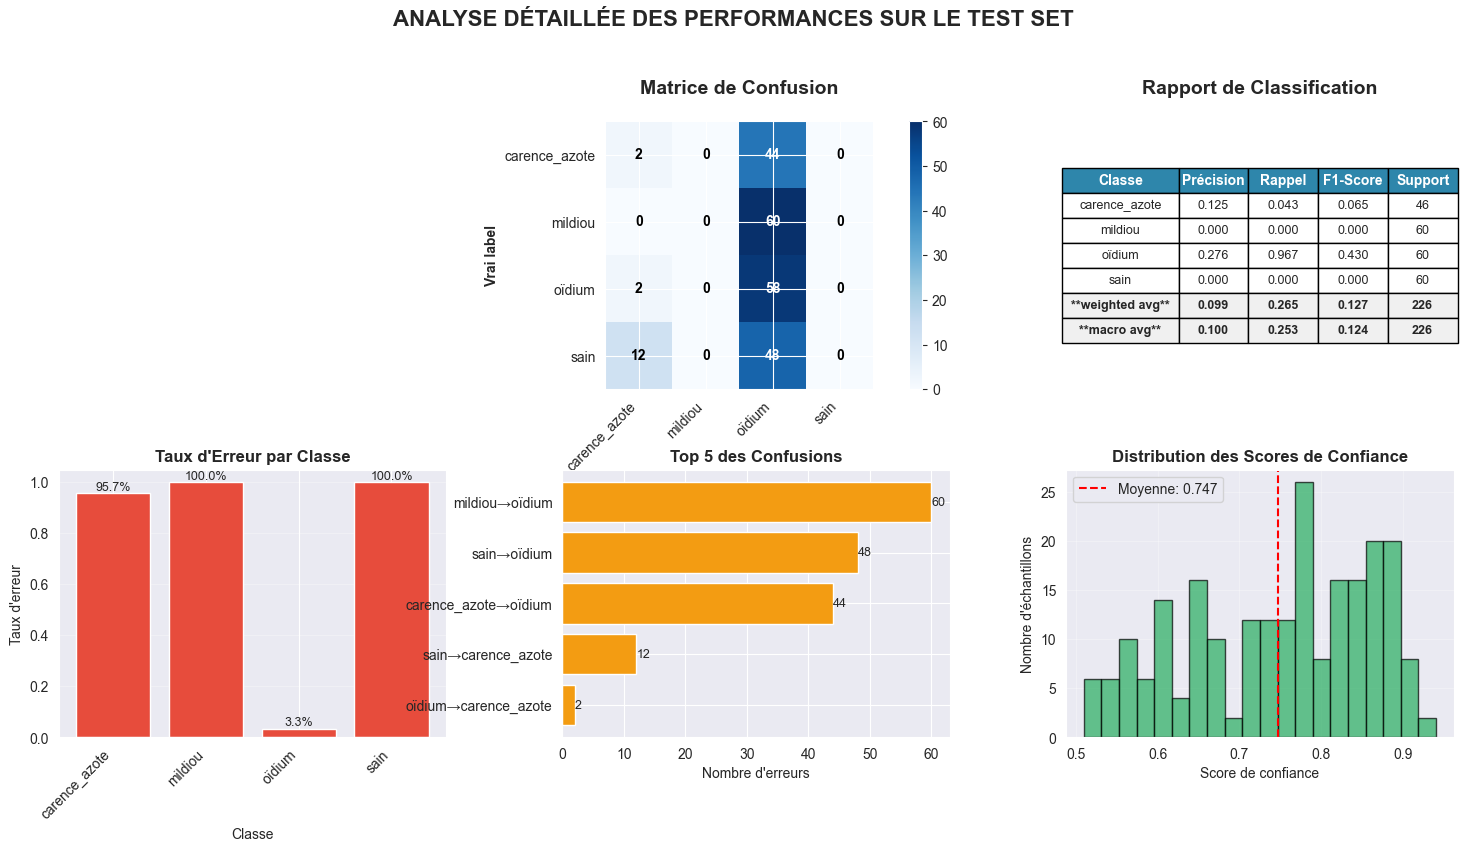


📸 Graphique sauvegardé: backend\models\baseline_test_evaluation.png

🔍 ANALYSE DÉTAILLÉE

📊 Accuracy par classe:
  carence_azote: 0.043 (46 échantillons)
  mildiou: 0.000 (60 échantillons)
  oïdium: 0.967 (60 échantillons)
  sain: 0.000 (60 échantillons)

🎯 Paires de classes les plus confondues:
  mildiou → oïdium: 60 erreurs (100.0% des mildiou)
  sain → oïdium: 48 erreurs (80.0% des sain)
  carence_azote → oïdium: 44 erreurs (95.7% des carence_azote)

📈 RÉSUMÉ DES PERFORMANCES

❌ À AMÉLIORER - Accuracy: 0.265 (26.5%)

💡 Recommandations:
  • Augmenter la taille du dataset
  • Améliorer l'augmentation de données
  • Essayer le transfer learning


In [31]:
# ==================== ÉVALUATION DU MODÈLE BASELINE ====================
# Ce bloc exécute l'évaluation complète du modèle baseline sur le jeu de test.
# Il calcule les métriques de performance (accuracy, precision, recall, AUC)
# et génère des visualisations comme la matrice de confusion pour analyser
# les types d'erreurs du modèle sur chaque classe de maladie. 

# Cellule 6 - Évaluation
test_metrics = evaluate_model_on_test(baseline_model, X_test, y_test_onehot, class_names)

In [34]:
# ==================== SAUVEGARDE DU MODÈLE ET DES RÉSULTATS ====================
# Ce bloc gère la sauvegarde complète du modèle baseline entraîné, de son historique
# d'entraînement, et des métriques d'évaluation. Cela permet de conserver une trace
# reproductible des expérimentations et de réutiliser le modèle pour des prédictions.

# Cellule 7 - Sauvegarde
def save_baseline_model(model, history, test_metrics, class_names, training_time):
    # Votre fonction de sauvegarde ici
    pass

saved_files = save_baseline_model(
    model=baseline_model,
    history=history,
    test_metrics=test_metrics,
    class_names=class_names,
    training_time=training_time
)